# Notebook de revizuire: primul pas al pass rusherilor (NFL Big Data Bowl 2027)

Notebook-ul arată tot ce am făcut până acum, astfel încât **să poată fi citit și criticat fără acces la date**. A fost rulat pe datele Kaggle, iar toate rezultatele (tabele și grafice) sunt salvate în el.

- **Ce conține:** codul măsurătorilor, validările, stabilitatea, testele pre-înregistrate H1–H4, toate verificările de robustețe, coeficienții modelelor, răspunsurile la recenzie și lista deciziilor care pot fi contestate.
- **Ce nu conține:** rânduri din datele competiției sau valori pe jucător. Regulile Kaggle nu permit redistribuirea datelor, așa că toate rezultatele sunt agregate.
- **Cum se refac:** cu datele descărcate, `bash run_all.sh`, apoi `python dl_first_step/make_review_notebook.py`.

**Conținut**
1. Datele și eșantionul
2. Cum măsurăm primul pas
3. Cât de stabile sunt măsurile
4. Testele pre-înregistrate și verificările de robustețe
5. H1 și H2: Combine → primul pas din NFL
6. H3: primul pas din meci și presiunea
7. H4: Combine → presiune
8. Deciziile care pot fi contestate
9. Întrebări deschise, unde ar ajuta propunerile

In [1]:
import inspect, json, os, sys
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import Image, display

ROOT = os.path.abspath(".")
sys.path.insert(0, os.path.join(ROOT, "dl_first_step"))
import common

DATA = os.path.join(ROOT, "nfl-big-data-bowl-2027")
OUT = os.path.join(ROOT, "dl_first_step", "outputs")
FIG = os.path.join(ROOT, "dl_first_step", "figures")
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
BLUE, ORANGE, AQUA, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#e1e0d9"
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "figure.dpi": 110})


def ci(v, nd=3):
    return f"[{v[0]:+.{nd}f}, {v[1]:+.{nd}f}]"


tests = json.load(open(os.path.join(OUT, "tests_results_rushers_only.json")))
tests_aw = json.load(open(os.path.join(OUT, "tests_results_as_written.json")))
rev = json.load(open(os.path.join(OUT, "review_round2.json")))
plays = pl.read_parquet(os.path.join(OUT, "game_rush_plays.parquet"))
creps = pl.read_parquet(os.path.join(OUT, "combine_reps.parquet"))
cdl = pl.read_parquet(os.path.join(OUT, "combine_dl_players.parquet"))
elig = plays.filter(pl.col("stance_start") & pl.col("lined_up_position").is_in(["EDGE", "INTERIOR_LINE"])
                    & (pl.col("play_nullified_by_penalty") == "N") & (pl.col("blitzing") == True))
print(f"faze eligibile: {elig.height:,}; jucători: {elig['nfl_id'].n_unique()}")

faze eligibile: 26,133; jucători: 98


## 1. Datele și eșantionul

Folosim **sezonul regulat 2023–2025** și jucătorii înscriși la Combine ca DL. Fazele de pass rush sunt rândurile din `player_play` cu `sack` completat. Tabelul arată cum se reduce numărul de faze la fiecare filtru.

In [2]:
steps = [
    ("faze de pass rush DL în sezonul regulat, cu tracking și snap", plays),
    ("start din poziție statică (sub 1 yd/s la snap)", plays.filter(pl.col("stance_start"))),
    ("aliniere edge sau interior", plays.filter(pl.col("stance_start") & pl.col("lined_up_position").is_in(["EDGE", "INTERIOR_LINE"]))),
    ("faza nu e anulată de penalizare", plays.filter(pl.col("stance_start") & pl.col("lined_up_position").is_in(["EDGE", "INTERIOR_LINE"])
                                                     & (pl.col("play_nullified_by_penalty") == "N"))),
    ("jucătorul chiar a atacat (nu s-a retras în acoperire)", elig),
]
pd.DataFrame([{"filtru": s, "faze": d.height, "jucători": d["nfl_id"].n_unique()} for s, d in steps])

,filtru,faze,jucători
0,"faze de pass rush DL în sezonul regulat, cu tracking și snap",28961,98
1,start din poziție statică (sub 1 yd/s la snap),27689,98
2,aliniere edge sau interior,27389,98
3,faza nu e anulată de penalizare,27389,98
4,jucătorul chiar a atacat (nu s-a retras în acoperire),26133,98


Pe sezoane și pe aliniere: volumul, presiunea și valorile tipice ale celor două măsuri principale.

In [3]:
(elig.group_by("season", "lined_up_position")
     .agg(pl.len().alias("faze"), pl.col("nfl_id").n_unique().alias("jucători"),
          (pl.col("pressure").mean() * 100).round(1).alias("presiune %"),
          pl.col("burst_15").median().round(3).alias("primul pas, mediana (s)"),
          pl.col("t_react").median().round(3).alias("reacția, mediana (s)"))
     .sort("season", "lined_up_position").to_pandas())

,season,lined_up_position,faze,jucători,presiune %,"primul pas, mediana (s)","reacția, mediana (s)"
0,2023,EDGE,2269,24,11.3,0.599,0.261
1,2023,INTERIOR_LINE,1442,21,6.9,0.692,0.296
2,2024,EDGE,4917,51,12.0,0.626,0.246
3,2024,INTERIOR_LINE,3509,47,7.4,0.704,0.279
4,2025,EDGE,7028,77,11.4,0.619,0.262
5,2025,INTERIOR_LINE,6968,80,7.5,0.695,0.290


**Eșantionul pe jucători** (pentru H1, H2 și H4). Prima tabelă arată cum se ajunge la cei 62 de jucători. A doua compară cei 62 cu cei 17 excluși, pentru a vedea dacă excluderea introduce o deformare.

In [4]:
s = rev["sample"]
display(pd.DataFrame([
    {"pas": "jucători DL cu faze eligibile", "jucători": s["dl_with_rushes"]},
    {"pas": "cu cel puțin 50 de faze", "jucători": s["ge50"]},
    {"pas": "și cu o repetare curată la 40 de yarzi (eșantionul principal)", "jucători": s["main"]},
    {"pas": "excluși: fără 40 curat", "jucători": s["no_clean_forty"]},
    {"pas": "   din care au sărit oficial peste 40", "jucători": s["skipped_forty_officially"]}]))
names = {"pick": "locul la draft (nedraftați = 260)", "eb_global": "rata de presiune (shrinkage)", "g_burst15": "primul pas în NFL (s)",
         "combine_weight": "greutate (lb)", "edge_share": "proporția fazelor pe edge", "rushes": "faze"}
pd.DataFrame([{"măsură": names[k], "mediana, cei 62": v["main_median"], "mediana, cei 17 excluși": v["missing_median"],
               "Mann-Whitney p": v["p"]} for k, v in rev["missing_vs_main"].items()])

,pas,jucători
0,jucători DL cu faze eligibile,98
1,cu cel puțin 50 de faze,79
2,și cu o repetare curată la 40 de yarzi (eșantionul principal),62
3,excluși: fără 40 curat,17
4,din care au sărit oficial peste 40,16


,măsură,"mediana, cei 62","mediana, cei 17 excluși",Mann-Whitney p
0,locul la draft (nedraftați = 260),124.000,66.000,0.108
1,rata de presiune (shrinkage),0.080,0.078,1.000
2,primul pas în NFL (s),0.715,0.677,0.374
3,greutate (lb),282.500,264.000,0.438
4,proporția fazelor pe edge,0.193,0.883,0.228
5,faze,191.000,252.000,0.659


## 2. Cum măsurăm primul pas

**Problema.** La Combine, înregistrarea începe cu jucătorul deja în mișcare, iar momentul tăierii variază. De aceea toate măsurile pornesc din momentul în care viteza atinge **1 yd/s**, interpolat între cadre. Distanța se măsoară din poziția din acel moment. Aceeași funcție e folosită la Combine și în meci.

In [5]:
print(inspect.getsource(common.first_crossing))
print(inspect.getsource(common.anchored_measures))

def first_crossing(df, keys, tcol, vcol, thr, name):
    """Time at which `vcol` first reaches `thr` in each group, interpolated between frames.

    `df` must be sorted by keys + tcol. Groups whose first value is already at or above
    `thr` get null, because their start was not recorded.
    """
    d = df.select(keys + [tcol, vcol]).with_columns(
        pl.col(vcol).shift(1).over(keys).alias("_vp"),
        pl.col(tcol).shift(1).over(keys).alias("_tp"),
    )
    hit = (d.filter((pl.col(vcol) >= thr) & (pl.col("_vp") < thr))
           .group_by(keys).agg(pl.all().sort_by(tcol).first()))
    t = pl.col("_tp") + (thr - pl.col("_vp")) / (pl.col(vcol) - pl.col("_vp")) * (pl.col(tcol) - pl.col("_tp"))
    res = hit.select(keys + [t.alias(name)])
    v0 = d.group_by(keys).agg(pl.col(vcol).sort_by(tcol).first().alias("_v0"))
    return (res.join(v0, on=keys)
            .with_columns(pl.when(pl.col("_v0") >= thr).then(None).otherwise(pl.col(name)).alias(name))
            .drop("_v0"))


**Validare: timpii din tracking față de cronometrul oficial** (toate pozițiile, cea mai bună încercare). La 40 de yarzi se potrivesc bine. La 10 yarzi se potrivesc slab, pentru că tăierea variabilă a începutului contează mult pe o distanță scurtă. De aici vine ancorarea la 1 yd/s.

In [6]:
cmb = common.read(DATA, "combine_results.csv").select("nfl_id", "combine_position", "ten_yd_split", "forty")
forty = creps.filter(pl.col("drill_name") == "FORTY_YARD_DASH")
best = forty.group_by("nfl_id").agg(pl.col("t_10").min().alias("t10"), pl.col("t_40").min().alias("t40")).join(cmb, on="nfl_id")
rows = []
for a, b, label in (("t10", "ten_yd_split", "10 yarzi, din primul cadru"), ("t40", "forty", "40 de yarzi, din primul cadru")):
    d = best.drop_nulls([a, b])
    diff = d[a] - d[b]
    rows.append({"timp": label, "jucători": d.height, "r cu timpul oficial": float(np.corrcoef(d[a], d[b])[0, 1]),
                 "tracking minus oficial (s)": float(diff.mean()), "abaterea standard a diferenței (s)": float(diff.std())})
display(pd.DataFrame(rows))
pd.DataFrame([{"grupă la Combine": g, "repetări la 40": n, "viteza în primul cadru, mediana (yd/s)": round(m, 2),
               "start curat (sub 1 yd/s)": round(c, 3)}
              for g, n, m, c in forty.group_by("combine_position").agg(pl.len(), pl.col("s_first").median().alias("med"),
                                                                       (pl.col("s_first") < 1).mean().alias("clean"))
              .sort("combine_position").rows()])

,timp,jucători,r cu timpul oficial,tracking minus oficial (s),abaterea standard a diferenței (s)
0,"10 yarzi, din primul cadru",418,0.469,0.332,0.133
1,"40 de yarzi, din primul cadru",381,0.912,0.319,0.133


,grupă la Combine,repetări la 40,"viteza în primul cadru, mediana (yd/s)",start curat (sub 1 yd/s)
0,DB,195,0.66,0.923
1,DL,177,0.65,0.938
2,OL,179,0.63,0.933
3,TE,66,0.64,0.848
4,WR,176,0.54,0.960


**Distribuțiile.** În stânga e primul pas: la Combine (40 de yarzi, DL) și în meci, pe aliniere. Valorile din meci de peste 1,4 s sunt adunate în ultima bară. În dreapta e reacția la snap.

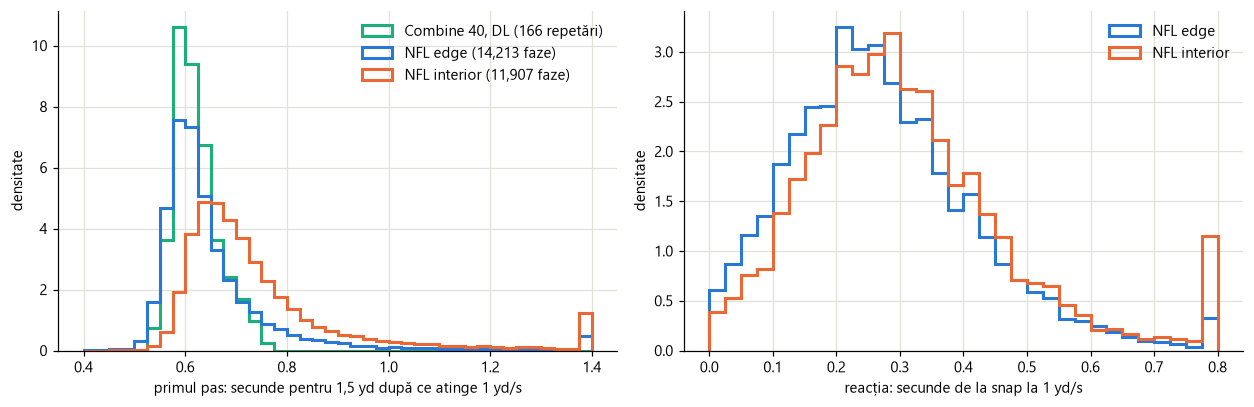

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
bins = np.linspace(0.4, 1.4, 41)
c = creps.filter((pl.col("drill_name") == "FORTY_YARD_DASH") & (pl.col("combine_position") == "DL"))["burst_15"].drop_nulls()
ax[0].hist(c.to_numpy(), bins=bins, density=True, histtype="step", lw=2, color=AQUA, label=f"Combine 40, DL ({c.len()} repetări)")
for key, color, label in (("EDGE", BLUE, "NFL edge"), ("INTERIOR_LINE", ORANGE, "NFL interior")):
    g = elig.filter(pl.col("lined_up_position") == key)["burst_15"].drop_nulls().clip(upper_bound=1.399)
    ax[0].hist(g.to_numpy(), bins=bins, density=True, histtype="step", lw=2, color=color, label=f"{label} ({g.len():,} faze)")
    r = elig.filter(pl.col("lined_up_position") == key)["t_react"].drop_nulls().clip(upper_bound=0.799)
    ax[1].hist(r.to_numpy(), bins=np.linspace(0, 0.8, 33), density=True, histtype="step", lw=2, color=color, label=label)
ax[0].set_xlabel("primul pas: secunde pentru 1,5 yd după ce atinge 1 yd/s")
ax[1].set_xlabel("reacția: secunde de la snap la 1 yd/s")
for a in ax:
    a.set_ylabel("densitate")
    a.legend(frameon=False)
plt.tight_layout()

**Viteza în jurul snap-ului.** Viteza raportată și viteza calculată din schimbarea poziției cresc amândouă cu circa 0,2 s înainte de cadrul snap-ului. Deci nu e un efect de netezire: fie cadrul snap-ului e ușor întârziat, fie jucătorii anticipează. În ambele cazuri, asta afectează doar reacția, nu primul pas.

In [8]:
pd.DataFrame(rev["snap_speed"]).rename(columns={"t": "secunde față de snap", "s_median": "viteza raportată, mediana",
                                                "step_speed_median": "viteza din poziție, mediana",
                                                "share_s_over_1": "proporția peste 1 yd/s"})

,secunde față de snap,"viteza raportată, mediana","viteza din poziție, mediana",proporția peste 1 yd/s
0,-0.5,0.02,0.100,0.004
1,-0.4,0.02,0.100,0.002
2,-0.3,0.02,0.100,0.001
3,-0.2,0.04,0.100,0.001
4,-0.1,0.09,0.200,0.000
5,0.0,0.23,0.300,0.000
6,0.1,0.45,0.500,0.083
7,0.2,0.75,0.728,0.288
8,0.3,1.10,1.077,0.579


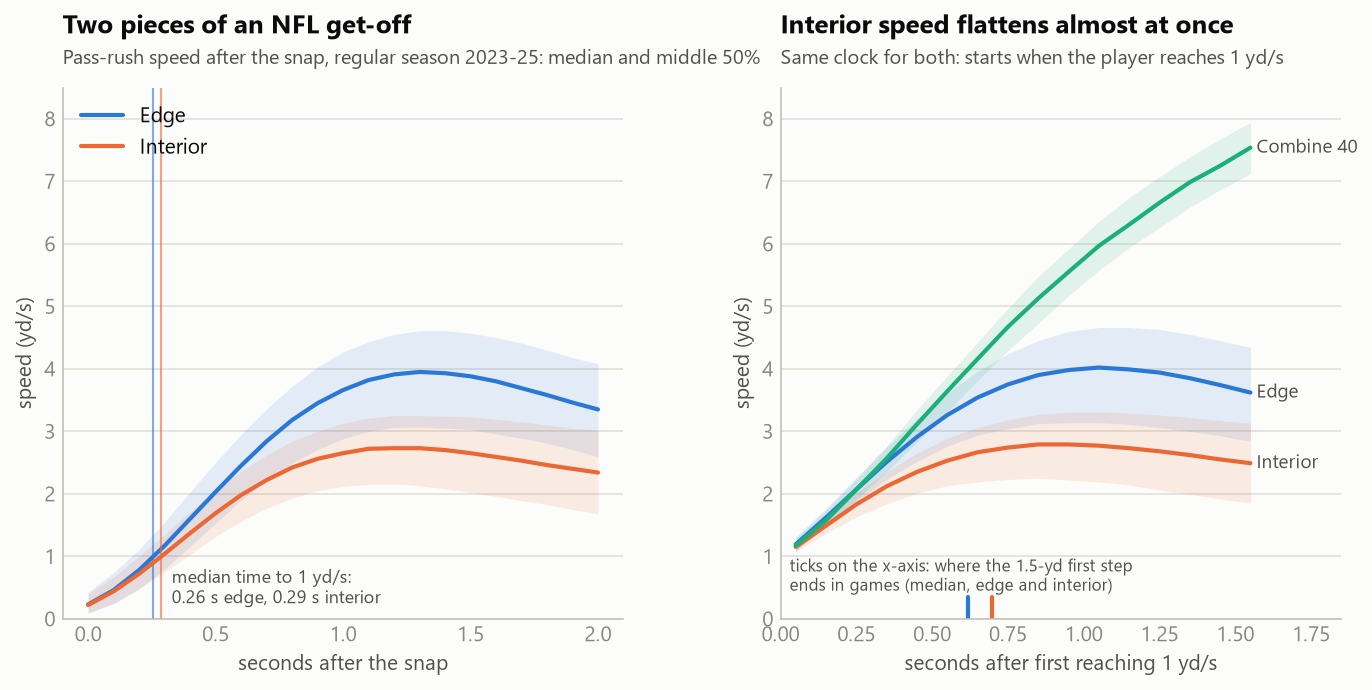

In [9]:
display(Image(filename=os.path.join(FIG, "f1_speed_curves.png")))

## 3. Cât de stabile sunt măsurile

Stabilitatea arată ce parte din diferențele dintre jucători e reală și ce parte e zgomot. Se calculează din meciurile pare față de cele impare, sau din încercările de la Combine, cu corecția Spearman-Brown pentru jucător.

- **„Un snap” sau „o încercare”** înseamnă stabilitatea unei singure măsurători.
- **„Ajustat pe rol”** înseamnă că fiecare fază e comparată cu media alinierii ei, ca diferența edge–interior să nu umfle rezultatul.

In [10]:
names = {"burst_15": "primul pas 1,5 yd", "burst_05": "primul pas 0,5 yd", "acc_02": "accelerația în primele 0,2 s", "t_react": "reacția la snap"}
cols = {"combine_single_attempt": "Combine: o încercare", "combine_mean_of_attempts": "Combine: media încercărilor",
        "nfl_single_play_role_adjusted": "NFL: un snap", "nfl_season_mixed_roles": "NFL: sezon, roluri amestecate",
        "nfl_season_role_adjusted": "NFL: sezon, ajustat pe rol", "nfl_season_EDGE": "NFL: sezon, doar edge",
        "nfl_season_INTERIOR_LINE": "NFL: sezon, doar interior"}
pd.DataFrame([{"măsură": names[k], **{lab: v.get(c) for c, lab in cols.items()}} for k, v in rev["reliability"].items()]).set_index("măsură")

,Combine: o încercare,Combine: media încercărilor,NFL: un snap,"NFL: sezon, roluri amestecate","NFL: sezon, ajustat pe rol","NFL: sezon, doar edge","NFL: sezon, doar interior"
măsură,,,,,,,
"primul pas 1,5 yd",0.599,0.749,0.012,0.944,0.800,0.798,0.851
"primul pas 0,5 yd",0.498,0.665,0.061,0.951,0.925,0.881,0.901
"accelerația în primele 0,2 s",0.608,0.756,0.039,0.970,0.871,0.914,0.921
reacția la snap,NaN,NaN,0.049,0.865,0.860,0.929,0.791


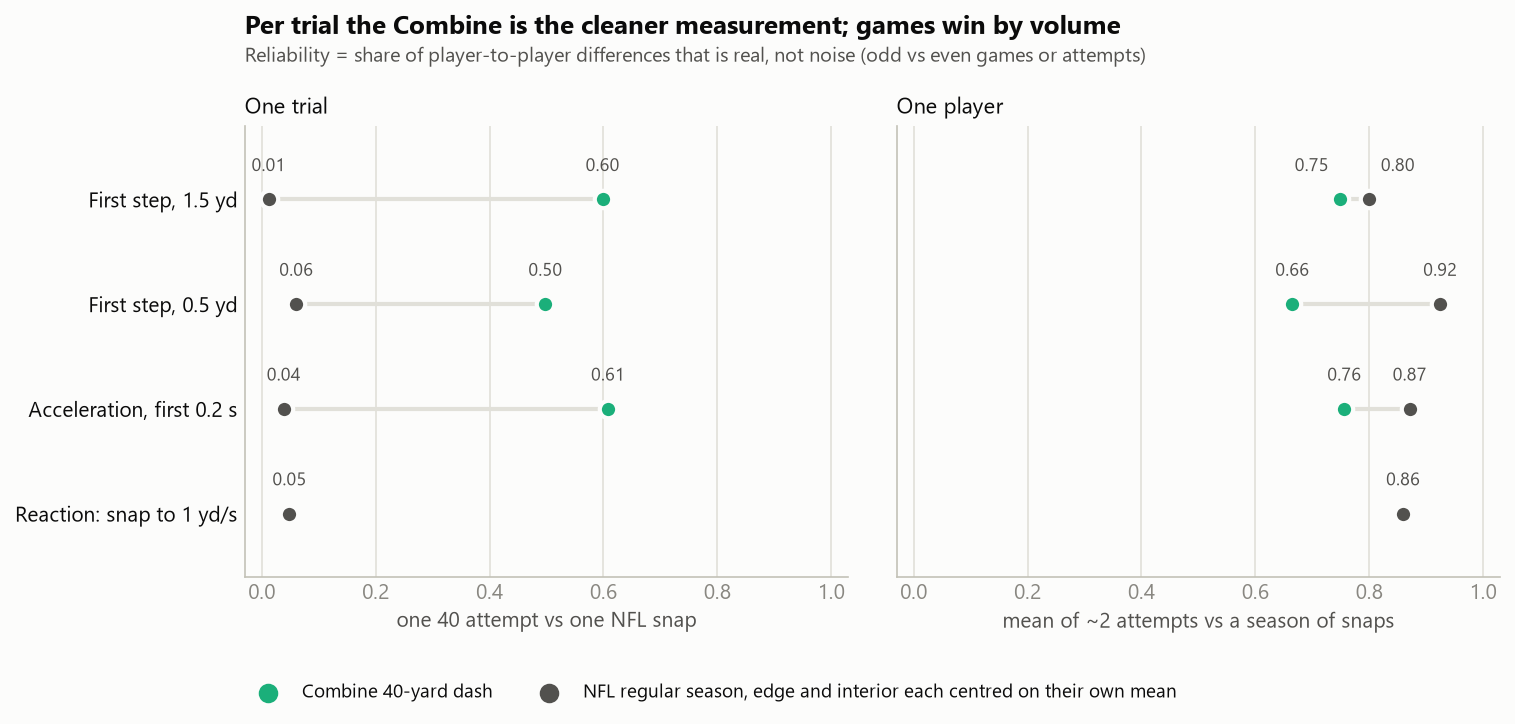

In [11]:
display(Image(filename=os.path.join(FIG, "f2_reliability.png")))

## 4. Testele pre-înregistrate și verificările de robustețe

Ipotezele au fost scrise în `ANALYSIS_PLAN.md` înainte de orice test. Testele principale sunt H1, H3 și H4, cu corecția Holm. H2 e descriptiv.

- **Definiția din plan:** toate rândurile cu `sack` completat.
- **Definiția corectată:** scoate cele 4,6% faze în care jucătorul s-a retras în acoperire.

In [12]:
def row(r, label):
    return {"varianta": label, "jucători": r["sample"]["players"], "faze eligibile": r["sample"]["eligible_plays"],
            "H1: r": r["H1"]["r"], "H1: IC 95%": ci(r["H1"]["ci"]),
            "H1: după greutate și rol (SD)": r["H1"]["adjusted_beta_std"], "H1: IC după controale": ci(r["H1"]["adjusted_ci_std"]),
            "H3: OR pe SD mai lent": r["H3"]["or"], "H3: IC 95%": ci(r["H3"]["or_ci"]),
            "H3: presiune la 1 SD mai rapid / mai lent": f"{100 * r['H3']['rate_fast_1sd']:.1f}% / {100 * r['H3']['rate_slow_1sd']:.1f}%",
            "H4: coeficient (pe secundă)": r["H4"]["coef"], "H4: IC bootstrap": ci(r["H4"]["coef_ci_boot"]),
            "Holm p, H1": r["holm"]["H1"], "Holm p, H3": r["holm"]["H3"], "Holm p, H4": r["holm"]["H4"]}


pd.DataFrame([row(tests_aw, "definiția din plan"), row(tests, "definiția corectată")]).set_index("varianta").T

varianta,definiția din plan,definiția corectată
jucători,62,62
faze eligibile,27389,26133
H1: r,0.209,0.202
H1: IC 95%,"[-0.009, +0.452]","[-0.022, +0.450]"
H1: după greutate și rol (SD),0.028,0.022
H1: IC după controale,"[-0.121, +0.177]","[-0.120, +0.164]"
H3: OR pe SD mai lent,0.679,0.735
H3: IC 95%,"[+0.590, +0.780]","[+0.647, +0.835]"
H3: presiune la 1 SD mai rapid / mai lent,12.5% / 6.3%,12.4% / 7.2%
H4: coeficient (pe secundă),-0.078,-0.065


**Toate verificările de robustețe din plan**, cu definiția corectată. Pentru H3, OR < 1 înseamnă că un prim pas mai rapid merge cu mai multă presiune.

In [13]:
what = {"min30": "prag 30 de faze", "min100": "prag 100 de faze", "burst_25": "măsura de 2,5 yd", "acc_1to3": "accelerația 1→3 yd/s",
        "spearman": "corelația Spearman", "spearman_unadjusted": "Spearman, fără controale",
        "class2023": "doar clasa 2023", "class2024": "doar clasa 2024", "class2025": "doar clasa 2025",
        "class2023_unadjusted": "doar clasa 2023, fără controale", "class2024_unadjusted": "doar clasa 2024, fără controale",
        "class2025_unadjusted": "doar clasa 2025, fără controale", "mostly_EDGE": "jucători mai mult pe edge",
        "mostly_INTERIOR": "jucători mai mult la interior", "mostly_EDGE_unadjusted": "jucători mai mult pe edge, fără controale",
        "mostly_INTERIOR_unadjusted": "jucători mai mult la interior, fără controale", "EDGE": "doar fazele de edge",
        "INTERIOR_LINE": "doar fazele de interior", "no_unblocked": "fără presiunile neblocate", "all_players": "toți cei 98 de jucători"}
rows = []
for k, v in tests["robustness"].items():
    h, rest = k[:2], k[3:]
    if "or" in v:
        rows.append({"ipoteza": h, "verificare": what.get(rest, rest), "statistica": "OR pe SD mai lent", "valoare": v["or"],
                     "IC 95%": ci(v["or_ci"]), "p": v["p"], "n": f"{v['plays']:,} faze, {v['players']} jucători"})
    elif "r" in v:
        rows.append({"ipoteza": h, "verificare": what.get(rest, rest), "statistica": "r", "valoare": v["r"], "IC 95%": ci(v["ci"]),
                     "p": v["p"], "n": f"{v['n']} jucători"})
    else:
        rows.append({"ipoteza": h, "verificare": what.get(rest, rest), "statistica": "coeficient pe secundă", "valoare": v["coef"],
                     "IC 95%": "", "p": v["p"], "n": f"{v['n']} jucători" if "n" in v else ""})
pd.DataFrame(rows).sort_values(["ipoteza", "verificare"]).reset_index(drop=True)

,ipoteza,verificare,statistica,valoare,IC 95%,p,n
0,H1,accelerația 1→3 yd/s,r,0.267,"[+0.014, +0.522]",3.579e-02,62 jucători
1,H1,corelația Spearman,r,0.263,"[+0.018, +0.473]",3.908e-02,62 jucători
2,H1,doar clasa 2023,r,0.345,"[-0.118, +0.657]",9.141e-02,25 jucători
3,H1,doar clasa 2024,r,0.117,"[-0.209, +0.542]",5.939e-01,23 jucători
4,H1,doar clasa 2025,r,0.042,"[-0.501, +0.714]",8.864e-01,14 jucători
5,H1,jucători mai mult la interior,r,0.106,"[-0.237, +0.511]",5.521e-01,34 jucători
6,H1,jucători mai mult pe edge,r,0.028,"[-0.296, +0.368]",8.859e-01,28 jucători
7,H1,"măsura de 2,5 yd",r,0.245,"[+0.019, +0.486]",5.536e-02,62 jucători
8,H1,prag 100 de faze,r,0.170,"[-0.073, +0.448]",2.420e-01,49 jucători
9,H1,prag 30 de faze,r,0.177,"[-0.034, +0.415]",1.476e-01,68 jucători


## 5. H1 și H2: primul pas de la Combine → primul pas din NFL

- **H1:** primul pas de la Combine se regăsește în primul pas din meci?
- **H2:** ce explică, de fapt, primul pas din meci?

Ferestrele scurte și corecția pentru atenuare sunt **post-hoc**, adăugate după recenzie.

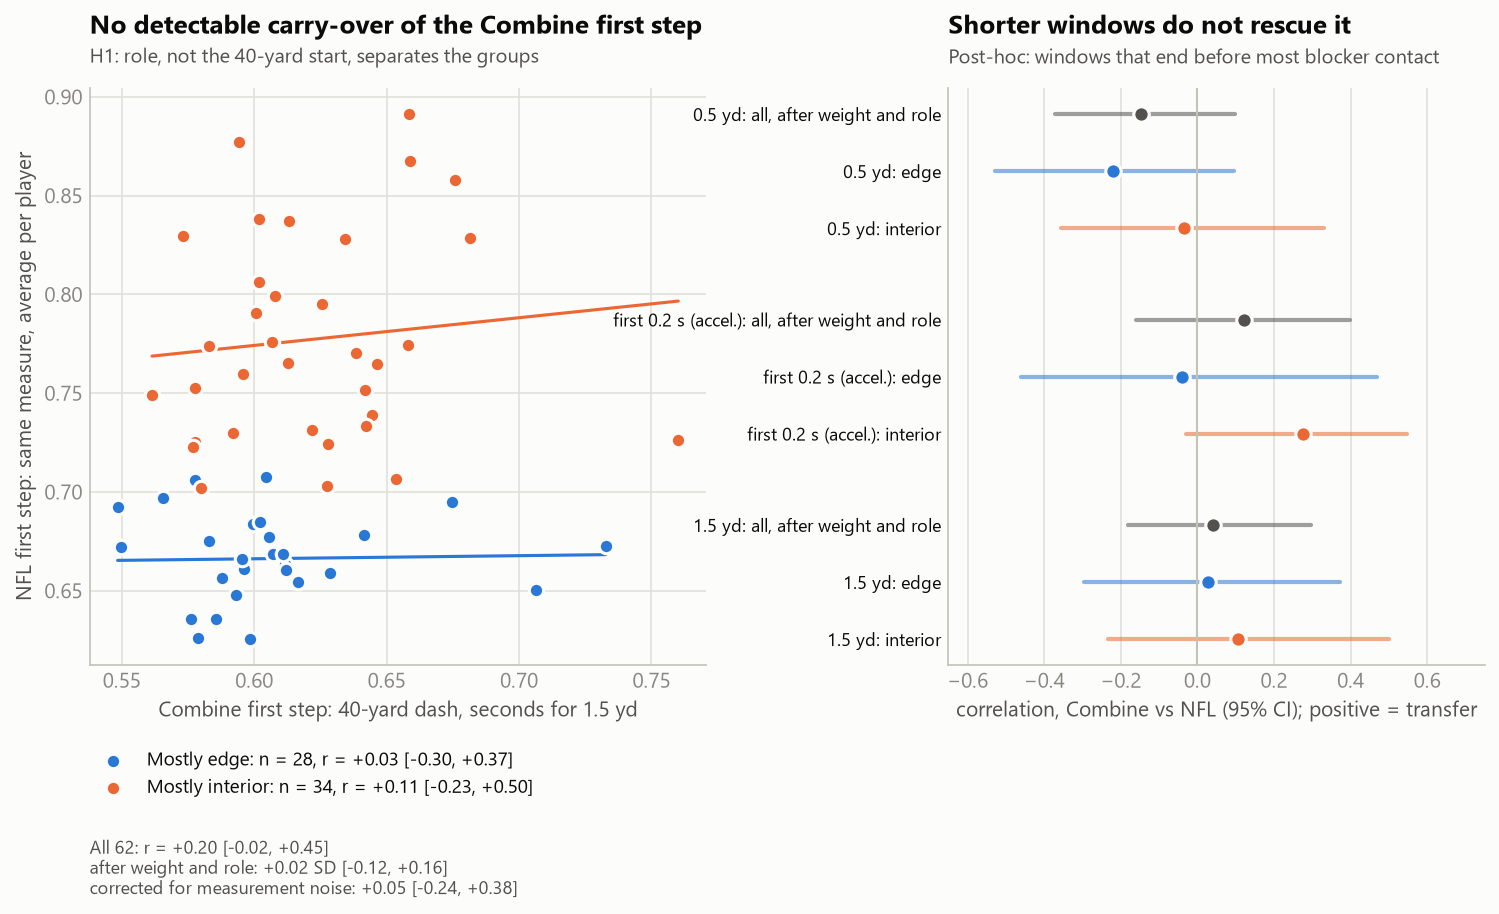

,fereastra,grup,r,IC 95%,n
0,0.5 yd,toți,0.024,"[-0.179, +0.252]",62
1,0.5 yd,"toți, după greutate și rol",-0.148,"[-0.371, +0.098]",62
2,0.5 yd,edge,-0.221,"[-0.527, +0.096]",28
3,0.5 yd,interior,-0.034,"[-0.356, +0.331]",34
4,first 0.2 s (accel.),toți,0.201,"[-0.056, +0.434]",62
5,first 0.2 s (accel.),"toți, după greutate și rol",0.122,"[-0.161, +0.398]",62
6,first 0.2 s (accel.),edge,-0.039,"[-0.461, +0.469]",28
7,first 0.2 s (accel.),interior,0.277,"[-0.030, +0.547]",34
8,1.5 yd,toți,0.202,"[-0.018, +0.453]",62
9,1.5 yd,"toți, după greutate și rol",0.040,"[-0.182, +0.297]",62


In [14]:
display(Image(filename=os.path.join(FIG, "f3_combine_vs_nfl.png")))
rows = []
for win, d in rev["transfer_by_window"].items():
    for g, lab in (("all", "toți"), ("partial_weight_role", "toți, după greutate și rol"), ("EDGE", "edge"), ("INTERIOR_LINE", "interior")):
        c = d[g]
        rows.append({"fereastra": win, "grup": lab, "r": c["r"], "IC 95%": ci(c["ci"]), "n": c["n"]})
pd.DataFrame(rows)

**Corecția pentru zgomotul de măsurare.** Plafonul e corelația maximă care s-ar putea observa dacă legătura reală ar fi perfectă, dat fiind cât de stabile sunt cele două măsuri.

In [15]:
d = rev["disattenuation"]
pd.DataFrame([{"comparație": "toți cei 62", "plafon": d["ceiling_all"], "r corectat": d["r_all_corrected"], "IC 95%": ci(d["ci_all_corrected"])},
              {"comparație": "după greutate și rol", "plafon": d["ceiling_partial"], "r corectat": d["r_partial_corrected"],
               "IC 95%": ci(d["ci_partial_corrected"])}])

,comparație,plafon,r corectat,IC 95%
0,toți cei 62,0.841,0.241,"[-0.022, +0.539]"
1,după greutate și rol,0.774,0.051,"[-0.236, +0.384]"


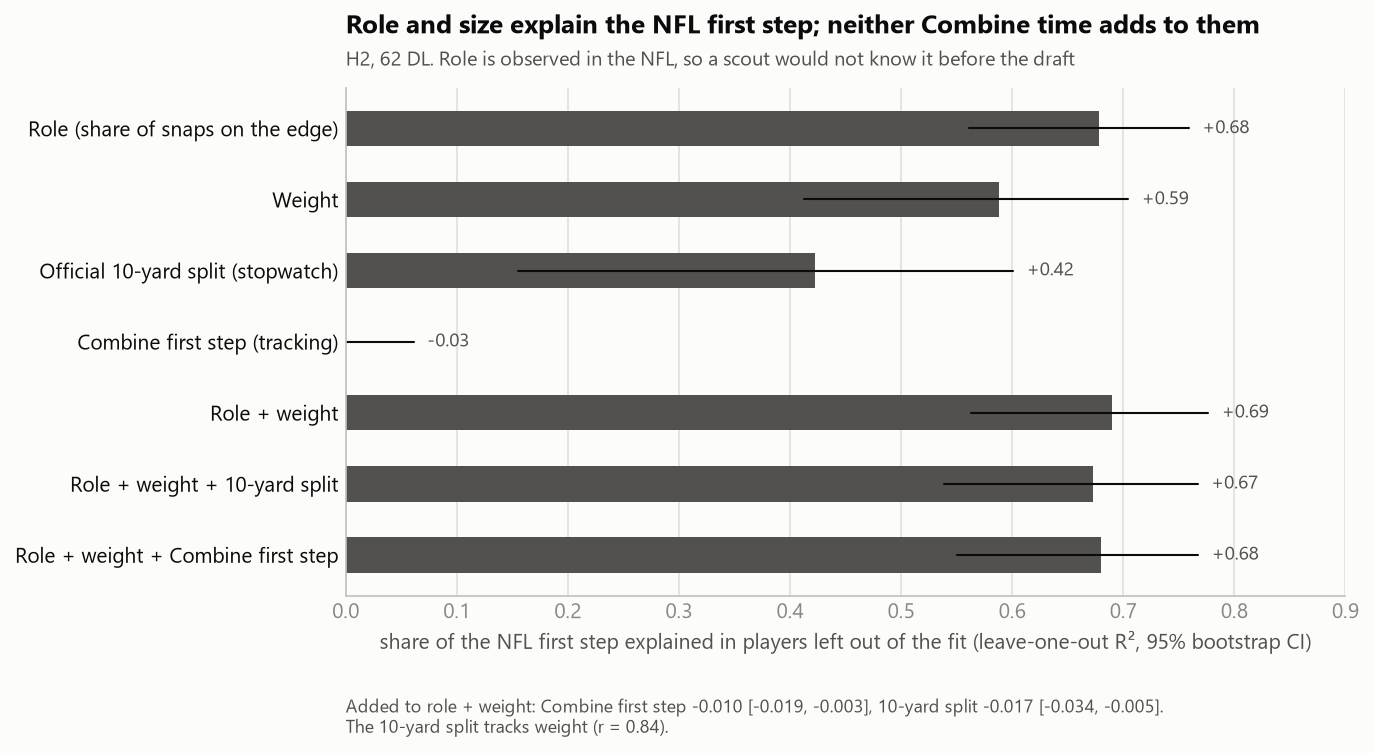

,model,R² leave-one-out,IC 95% (bootstrap pe jucători)
0,Role (share of snaps on the edge),0.678,"[+0.561, +0.759]"
1,Weight,0.588,"[+0.413, +0.705]"
2,Official 10-yard split (stopwatch),0.423,"[+0.155, +0.601]"
3,Combine first step (tracking),-0.034,"[-0.213, +0.061]"
4,Role + weight,0.690,"[+0.563, +0.777]"
5,Role + weight + 10-yard split,0.672,"[+0.539, +0.767]"
6,Role + weight + Combine first step,0.680,"[+0.550, +0.768]"
7,Role + weight + Combine first step minus Role + weight,-0.010,"[-0.019, -0.003]"
8,Role + weight + 10-yard split minus Role + weight,-0.017,"[-0.034, -0.005]"


In [16]:
display(Image(filename=os.path.join(FIG, "f4_what_explains_nfl_first_step.png")))
pd.DataFrame([{"model": k, "R² leave-one-out": v["r2"], "IC 95% (bootstrap pe jucători)": ci(v["ci"])} for k, v in rev["loo_r2"].items()])

## 6. H3: primul pas din meci și presiunea

**Modelul principal:** regresie logistică pe faze, pentru cei 62 de jucători. Erorile standard sunt grupate pe jucător. Toți coeficienții sunt afișați ca odds ratio, ca să se vadă și variabilele de control. `m_z` e primul pas standardizat în interiorul alinierii.

In [17]:
games = common.read(DATA, "games.csv")
gp = elig.group_by("nfl_id").agg(pl.len().alias("n"))
main_ids = gp.filter(pl.col("n") >= 50).join(cdl.filter(pl.col("forty_burst15_mean").is_not_null()), on="nfl_id").select("nfl_id")
d = (elig.join(main_ids, on="nfl_id", how="semi").join(games.select("game_id", "home_team_abbr"), on="game_id")
     .with_columns(pl.when(pl.col("team_abbr") == pl.col("home_team_abbr"))
                   .then(pl.col("pre_snap_home_score") - pl.col("pre_snap_visitor_score"))
                   .otherwise(pl.col("pre_snap_visitor_score") - pl.col("pre_snap_home_score")).alias("score_diff_def"),
                   (pl.col("lined_up_position") == "EDGE").cast(pl.Float64).alias("edge"),
                   pl.col("pressure").cast(pl.Float64).alias("pressure_f")))
rare = elig.group_by("offense_formation").len().filter(pl.col("len") < 100)["offense_formation"]
d = (d.with_columns(pl.when(pl.col("offense_formation").is_null() | pl.col("offense_formation").is_in(rare.drop_nulls().implode()))
                    .then(pl.lit("OTHER")).otherwise(pl.col("offense_formation")).alias("offense_formation"))
      .drop_nulls(["burst_15", "t_react", "down", "yards_to_go", "score_diff_def"])
      .with_columns(((pl.col("burst_15") - pl.col("burst_15").mean().over("lined_up_position"))
                     / pl.col("burst_15").std().over("lined_up_position")).alias("m_z")))
pdf = d.select("nfl_id", "pressure_f", "m_z", "t_react", "edge", "down", "yards_to_go", "offense_formation", "score_diff_def").to_pandas()
m = smf.logit("pressure_f ~ m_z + t_react + edge + C(down) + yards_to_go + C(offense_formation) + score_diff_def", data=pdf).fit(
    disp=False, maxiter=500, cov_type="cluster", cov_kwds={"groups": pdf["nfl_id"]})
print(f"faze: {int(m.nobs):,}; jucători: {pdf['nfl_id'].nunique()}; pseudo R²: {m.prsquared:.3f}")
cint = m.conf_int()
pd.DataFrame({"OR": np.exp(m.params), "IC jos": np.exp(cint[0]), "IC sus": np.exp(cint[1]), "p": m.pvalues})

faze: 20,012; jucători: 62; pseudo R²: 0.029


,OR,IC jos,IC sus,p
Intercept,0.087,0.069,0.110,2.721e-91
C(down)[T.2],1.066,0.937,1.214,3.329e-01
C(down)[T.3],1.506,1.321,1.718,1.009e-09
C(down)[T.4],1.417,1.096,1.833,7.929e-03
C(offense_formation)[T.I_FORM],1.247,0.848,1.834,2.617e-01
C(offense_formation)[T.JUMBO],0.592,0.196,1.789,3.526e-01
C(offense_formation)[T.OTHER],4.756,1.203,18.809,2.622e-02
C(offense_formation)[T.PISTOL],0.802,0.580,1.109,1.822e-01
C(offense_formation)[T.SHOTGUN],0.928,0.779,1.105,3.998e-01
C(offense_formation)[T.SINGLEBACK],1.076,0.846,1.369,5.497e-01


**Între jucători și în cadrul aceluiași jucător** (post-hoc). Componenta *within* compară fazele unui jucător cu propria lui medie. Varianta cu efecte fixe adaugă câte o variabilă indicator pentru fiecare jucător. Fereastra de 0,5 yd se termină înainte de cea mai mare parte a contactului.

,eșantion,măsura,în cadrul jucătorului: OR pe SD,IC,p,între jucători: OR pe SD,IC între,p între,efecte fixe: OR,IC efecte fixe,faze
0,main_62,burst_15,0.749,"[+0.665, +0.843]",1.755e-06,0.406,"[+0.195, +0.846]",1.604e-02,0.744,"[+0.661, +0.838]",20012
1,main_62,burst_05,0.875,"[+0.811, +0.944]",5.874e-04,0.870,"[+0.617, +1.228]",4.283e-01,0.858,"[+0.794, +0.927]",20020
2,main_62,acc_02,1.116,"[+1.057, +1.179]",6.890e-05,1.838,"[+1.341, +2.517]",1.511e-04,1.120,"[+1.061, +1.183]",20020
3,all_98,burst_15,0.726,"[+0.654, +0.807]",2.695e-09,0.391,"[+0.195, +0.782]",7.906e-03,0.718,"[+0.645, +0.799]",26120
4,all_98,burst_05,0.872,"[+0.818, +0.930]",2.769e-05,0.893,"[+0.665, +1.200]",4.539e-01,0.855,"[+0.801, +0.913]",26129
5,all_98,acc_02,1.143,"[+1.085, +1.205]",4.604e-07,1.949,"[+1.422, +2.673]",3.423e-05,1.146,"[+1.088, +1.207]",26129


acc_02 e o accelerație (mai mare = mai rapid), deci acolo OR > 1 înseamnă același lucru ca OR < 1 la primul pas.


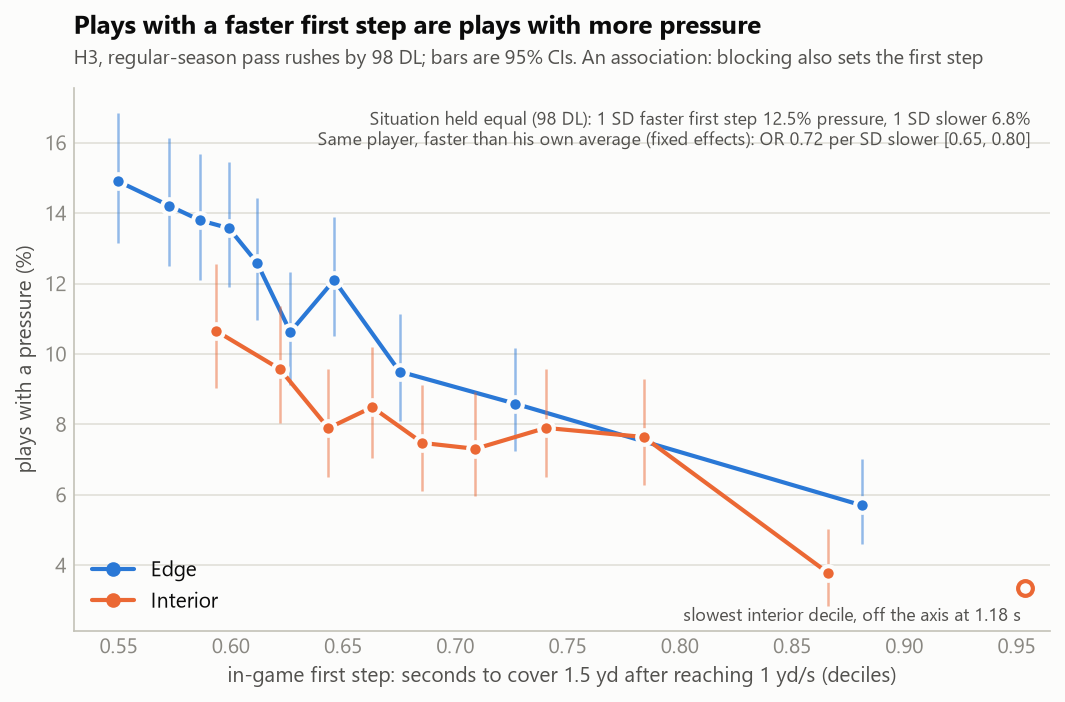

In [18]:
rows = []
for sample, block in rev["H3_decomposed"].items():
    for meas, v in block.items():
        rows.append({"eșantion": sample, "măsura": meas, "în cadrul jucătorului: OR pe SD": v["or_within_per_overall_sd"],
                     "IC": ci(v["or_within_ci"]), "p": v["p_within"], "între jucători: OR pe SD": v["or_between"],
                     "IC între": ci(v["or_between_ci"]), "p între": v["p_between"], "efecte fixe: OR": v["fixed_effects_or"],
                     "IC efecte fixe": ci(v["fixed_effects_ci"]), "faze": v["plays"]})
display(pd.DataFrame(rows))
print("acc_02 e o accelerație (mai mare = mai rapid), deci acolo OR > 1 înseamnă același lucru ca OR < 1 la primul pas.")
display(Image(filename=os.path.join(FIG, "f5_pressure_vs_first_step.png")))

## 7. H4: primul pas de la Combine → presiune

**Modelul H4:** regresie liniară pe jucători, cu erori HC3. Variabila dependentă e rata de presiune corectată pentru numărul de faze. Controalele sunt locul la draft (logaritmat), timpul pe 10 yarzi și proporția fazelor pe edge.

In [19]:
h4 = tests["H4"]
display(pd.DataFrame({"coeficient": h4["params"], "p (HC3)": h4["pvalues"]}))
print(f"R² = {h4['r2']:.3f}; coeficientul standardizat al primului pas de la Combine = {h4['beta_std']:+.3f}; "
      f"IC bootstrap {ci(h4['coef_ci_boot'], 4)}")
pd.DataFrame(tests["quartiles"]).rename(columns={"q": "sfertul după primul pas la Combine"})

,coeficient,p (HC3)
const,0.310,8.146e-07
forty_burst15_mean,-0.065,4.739e-01
log_pick,-0.010,4.271e-03
ten_yd_split,-0.086,2.346e-02
edge_share,0.018,2.114e-02


R² = 0.526; coeficientul standardizat al primului pas de la Combine = -0.102; IC bootstrap [-0.1939, +0.0881]


,sfertul după primul pas la Combine,players,combine_burst15,game_burst15,eb_pressure_rate,mean_pick_drafted,weight
0,Q1 fastest,16,0.574,0.702,0.089,114.2,273.6
1,Q2,15,0.598,0.721,0.088,96.8,270.5
2,Q3,15,0.618,0.729,0.085,114.8,291.3
3,Q4 slowest,16,0.670,0.757,0.076,109.8,299.0


**Pe roluri** (explorator). Semnalul de la interior e controlat pentru greutate și NT, iar rata de presiune e corectată spre media rolului. *Jackknife* înseamnă intervalul în care rămâne r când scoatem, pe rând, câte un jucător.

rol,INTERIOR_LINE,EDGE
poziții,"{'DE': 6, 'DT': 24, 'NT': 4}","{'DE': 17, 'OLB': 11}"
r (shrinkage global),-0.491,0.14
r (shrinkage pe rol),-0.489,0.158
IC,"[-0.693, -0.193]","[-0.140, +0.504]"
p,0.003,0.422
Spearman,-0.461,0.228
jackknife min/max,"[-0.53, -0.40]","[+0.04, +0.26]"
r parțial după greutate,-0.473,0.225
r parțial după greutate și NT,-0.479,NaN
beta standardizat,-0.469,0.229


pragul Bonferroni pentru circa 20 de verificări: 0.0025


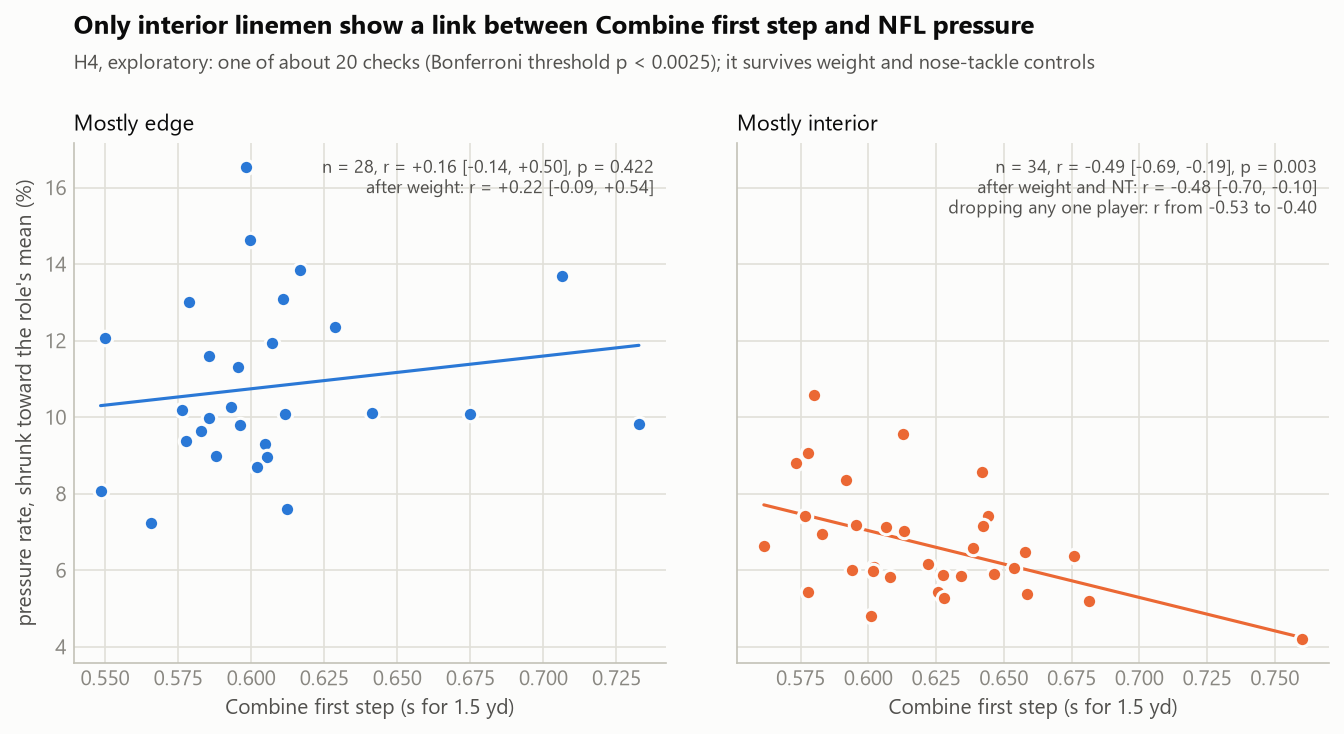

In [20]:
rows = []
for role, v in rev["pressure_by_role"].items():
    rows.append({"rol": role, "poziții": v["positions"], "r (shrinkage global)": v["r_global_shrink"]["r"],
                 "r (shrinkage pe rol)": v["r_group_shrink"]["r"], "IC": ci(v["r_group_shrink"]["ci"]), "p": v["r_group_shrink"]["p"],
                 "Spearman": v["spearman_group"], "jackknife min/max": ci(v["jackknife_min_max"], 2),
                 "r parțial după greutate": v["partial_weight"]["r"],
                 "r parțial după greutate și NT": v.get("partial_weight_nt", {}).get("r"),
                 "beta standardizat": v["ols_std_beta"], "p beta": v["ols_p"]})
display(pd.DataFrame(rows).set_index("rol").T)
print(f"pragul Bonferroni pentru circa 20 de verificări: {rev['bonferroni_threshold_20_checks']:.4f}")
display(Image(filename=os.path.join(FIG, "f6_pressure_by_role.png")))

## 8. Deciziile care pot fi contestate

Fiecare rând e o alegere care schimbă rezultatele. Pentru fiecare e notat unde se modifică în cod și ce alternativă merită discutată.

| Decizie | Valoarea aleasă | Unde în cod | De ce | Alternative |
|---|---|---|---|---|
| Ancora ceasului | viteza atinge 1 yd/s | `common.anchored_measures(s_on=1.0)` | Combine-ul taie variabil începutul | 0,5 sau 1,5 yd/s |
| Distanța primului pas | 1,5 yd | `game_starts.py`, `combine_starts.py` (`dist`) | la edge se termină de obicei înainte de contact | 0,5 sau 1 yd; o fereastră în timp |
| Start static | sub 1 yd/s la snap sau în primul cadru | `stance_start`, `clean_start` | același tip de start în ambele contexte | prag mai strict |
| Faza de pass rush | `sack` completat și `blitzing` adevărat | `tests.py` | `blitzing` înseamnă că jucătorul a atacat | doar fazele de pasă cu `pass_result` |
| Presiunea | `time_to_pressure` completat | `game_starts.py` | definiția NGS de presiune | doar sack; presiune rapidă |
| Prag de faze pe jucător | 50 | `tests.py` (`MIN_RUSHES`) | echilibru între stabilitate și eșantion | 30 și 100 au fost testate |
| Controalele din H3 | aliniere, down, distanță, formație, scor, reacție | `tests.py` (`logit_h3`) | context disponibil înainte de snap | sfertul, ceasul, adversarul |
| Modelul H4 | regresie liniară, HC3, log(locul la draft) | `tests.py` | simplu și transparent | model ierarhic pe toate fazele |
| Shrinkage | beta-binomial, spre media rolului | `figures.py`, `review_round2.py` | rate stabile pentru jucători cu puține faze | spre media globală (a dat același rezultat) |
| Linia de scrimmage | din `yardline_number`, ±0,5 yd | `game_starts.py` | nu există poziția mingii | nu e folosită în măsurile principale |
| Rolul unui jucător | edge dacă cel puțin 50% din faze sunt pe edge | `figures.py`, `review_round2.py` | rolul dominant | proporția ca variabilă continuă (folosită în H1 și H4) |

## 9. Întrebări deschise, unde ar ajuta propunerile

1. **Semnalul de la interior.** Rezistă controlului pentru greutate și NT, dar nu trece de pragul Bonferroni. Primul pas de la Combine nu prezice nici primul pas din NFL al acestor jucători. Ce ar putea măsura, de fapt? De exemplu, explozia în contact, nu viteza în spațiu liber. Ce măsură din exercițiile DL de la Combine ar putea testa asta? Atenție: aceste exerciții au o singură repetare pe jucător.
2. **H3 e o asociere.** Nu avem blocatorii în tracking, deci double team-urile și stunt-urile nu se pot controla. Există o variabilă din `player_play` care ar putea servi ca aproximare?
3. **Modelarea.** Ar fi mai bun un model ierarhic, de exemplu un logistic mixt pe toate fazele cu primul pas de la Combine ca predictor la nivel de jucător, în locul analizei în doi pași pentru H1 și H4?
4. **Povestea.** Lucrarea ar trebui să înceapă cu partea utilă pentru echipe (reacția și primul pas, măsurate din meciuri) și să pună rezultatul negativ de la Combine pe locul doi?
5. **Bugetul de figuri.** Sunt 6 figuri și un tabel, sub limita de 10. Ce ar merita adăugat sau scos?
6. **Claritatea.** Ce nu e clar în `WRITEUP_DRAFT.md` pentru un analist al unei echipe NFL?